In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())
describe(df)

Shape:  (2823, 25)

First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1           

In [4]:
cust = df.groupby("CUSTOMERNAME").agg(Frequency=("ORDERNUMBER","nunique"), Monetary=("SALES","sum")).reset_index()
print(cust.head())
X = StandardScaler().fit_transform(cust[["Frequency","Monetary"]])

              CUSTOMERNAME  Frequency   Monetary
0           AV Stores, Co.          3  157807.81
1             Alpha Cognac          3   70488.44
2       Amica Models & Co.          2   94117.26
3  Anna's Decorations, Ltd          4  153996.13
4        Atelier graphique          3   24179.96


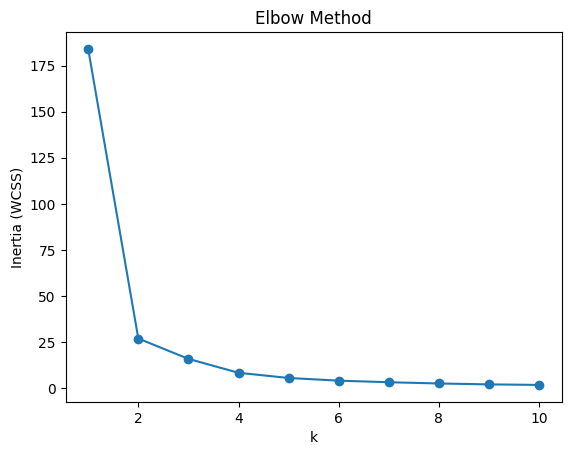

In [5]:
inertia = [KMeans(n_clusters=k,random_state=42,n_init=10).fit(X).inertia_ for k in range(1,11)]
plt.plot(range(1,11),inertia,marker="o"); plt.xlabel("k"); plt.ylabel("Inertia (WCSS)"); plt.title("Elbow Method"); plt.show()

k = 3                                                  # chosen at the elbow
cust["KMeans"] = KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(X)

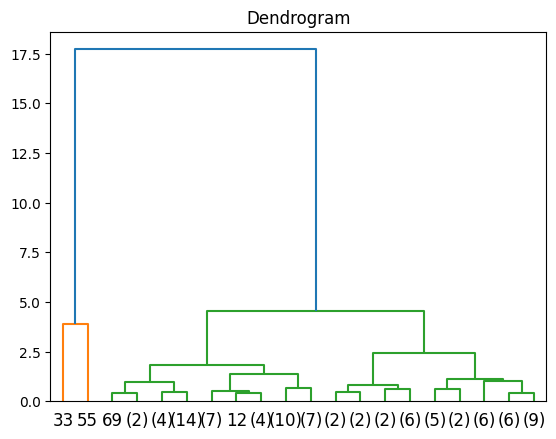

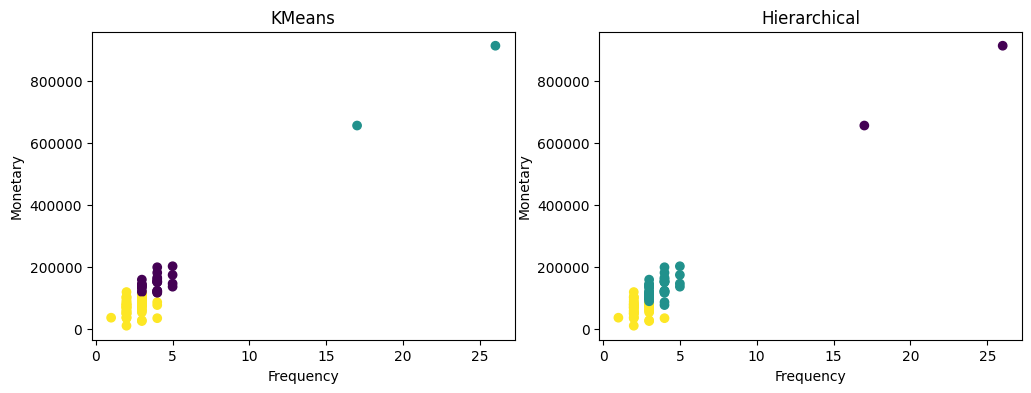

        Frequency       Monetary
KMeans                          
0        3.840000  145705.943200
1       21.500000  783576.085000
2        2.584615   74197.355385


In [6]:
dendrogram(linkage(X,method="ward"),truncate_mode="lastp",p=20); plt.title("Dendrogram"); plt.show()
cust["Hierarchical"] = AgglomerativeClustering(n_clusters=k,linkage="ward").fit_predict(X)

fig,ax = plt.subplots(1,2,figsize=(12,4))
for a,col in zip(ax,["KMeans","Hierarchical"]):
    a.scatter(cust["Frequency"],cust["Monetary"],c=cust[col],cmap="viridis"); a.set_title(col)
    a.set_xlabel("Frequency"); a.set_ylabel("Monetary")
plt.show()
print(cust.groupby("KMeans")[["Frequency","Monetary"]].mean())